In [1]:
import numpy as np 
import xarray as xr

import matplotlib.pyplot as plt 
import matplotlib as mpl
import matplotlib.gridspec as gs
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

import matplotlib.path as mpath
theta = np.linspace(0, 2*np.pi, 100)
center, radius = [0.5, 0.5], 0.5
verts = np.vstack([np.sin(theta), np.cos(theta)]).T
circle = mpath.Path(verts * radius + center)

%matplotlib inline
%config InlineBackend.figure_format='retina'

In [2]:

# this can be any Isca output run with the target resolution
f_coords = '/disca/share/ntl203/isca_data/ks_1triangle_exact_but_NHheat2_TROP_SPONGE_30m_0M_0C/run0001/atmos_yearly.nc'

ds_coords = xr.open_dataset(f_coords, 
                            decode_times=False)
lats = ds_coords.lat.values 
lons = ds_coords.lon.values 
lons_cartopy = np.arange(0,360,360/len(lons))



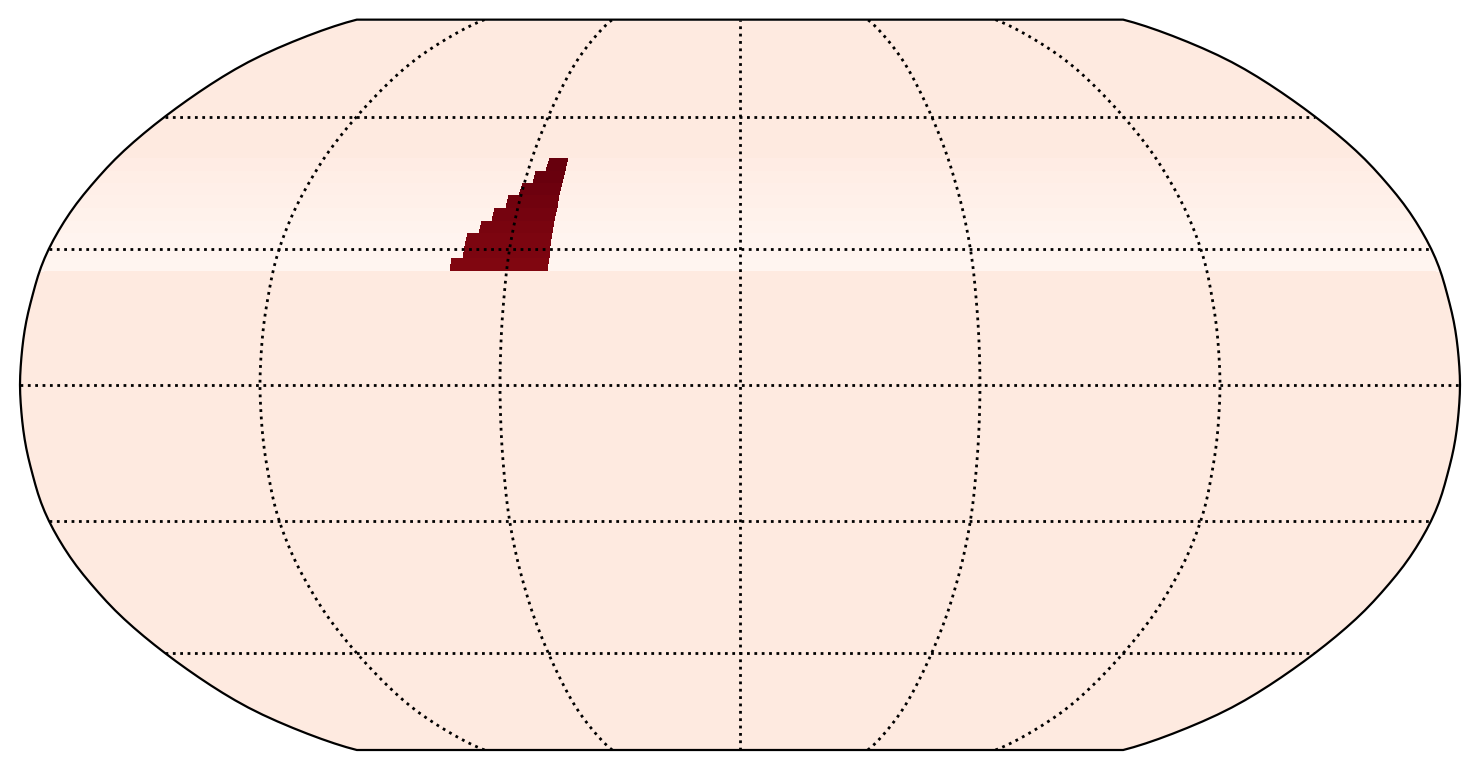

In [3]:
from pyproj import Geod
from scipy.interpolate import interp1d as interp 
g = Geod(sphere=True, a=1)
npts = 500

lon0 = 360-75
lonw = 25
lat0 = 25
latw = 25

latlon = g.npts(lon1=lon0-180, lon2=lon0+lonw-180, lat1=lat0, lat2=lat0+latw, npts=npts, terminus_idx=0, initial_idx=0)

latgs = np.empty(npts)
longs = np.empty(npts)
j =0 
for long,latg in latlon:
    latgs[j] = latg
    longs[j] = long+180
    j+=1
intp_func = interp(longs, latgs) # used to define relationship between lat and lon for heating triangle 'hypotenuse'
    



lons_grid = lons[(lons>lon0) & (lons<(lon0+lonw))]
lats_grid = intp_func(lons_grid)
lats_grid2 = np.zeros(len(lats_grid))
for i, lat in enumerate(lats_grid):
    lats_grid2[i] = lats[np.argmin(np.abs(lats-lat))]
lats_grid = lats_grid2


heating1 = np.ones((len(lats), len(lons)))
heating1[:,lons>(lon0+lonw)] = 0.
heating1[:,lons<lon0] = 0.
heating1[lats<lat0,:] = 0.
heating1[lats>lat0+latw,:] = 0.
for i, lon in enumerate(lons_grid):
    i_use = np.argmin(np.abs(lons-lon))
    heating1[lats>lats_grid[i],i_use] = 0.
    

    

zm_heating1 = np.mean(heating1, axis=-1)
heating1 -= zm_heating1[::1,None] # take off zonal mean so triangle adds no net heating to hemisphere. This is different to kaspi and schneider



# make grid 
grid = gs.GridSpec(1, 1, left=0.05, right=0.95, bottom=0.125, top=0.875, hspace=0.1)#-0.3)


# make figure 
fig = plt.figure(2, figsize=(8,8))
ax = fig.add_subplot(grid[0], projection=ccrs.Robinson(central_longitude=0))




ax.pcolormesh(lons,lats,heating1*850, transform=ccrs.PlateCarree(), cmap=plt.cm.Reds)
ax.set_global()
gl=ax.gridlines(draw_labels=False, dms=False, x_inline=True, y_inline=True, linewidth=1, color='k', linestyle=':')





In [4]:
#ds_dummy = xr.open_dataset('/home/links/ntl203/Isca/exp/test_cases/realistic_continents/input/ami_qflux_ctrl_ice_4320.nc', decode_times=False)



ds = xr.Dataset(coords=dict(lat=ds_coords.lat.values, 
                            lon=ds_coords.lon.values, 
                            latb=ds_coords.latb.values, 
                            lonb=ds_coords.lonb.values))

ds['qflux_1tri_NHheat2'] = xr.DataArray(data=heating1*850, coords=dict(lat=ds_coords.lat.values, lon=ds_coords.lon.values), dims=['lat','lon'])

ds.to_netcdf('qflux_1tri_NHheat2_halfed.nc')

TypeError: cannot directly convert an xarray.Dataset into a numpy array. Instead, create an xarray.DataArray first, either with indexing on the Dataset or by invoking the `to_dataarray()` method.

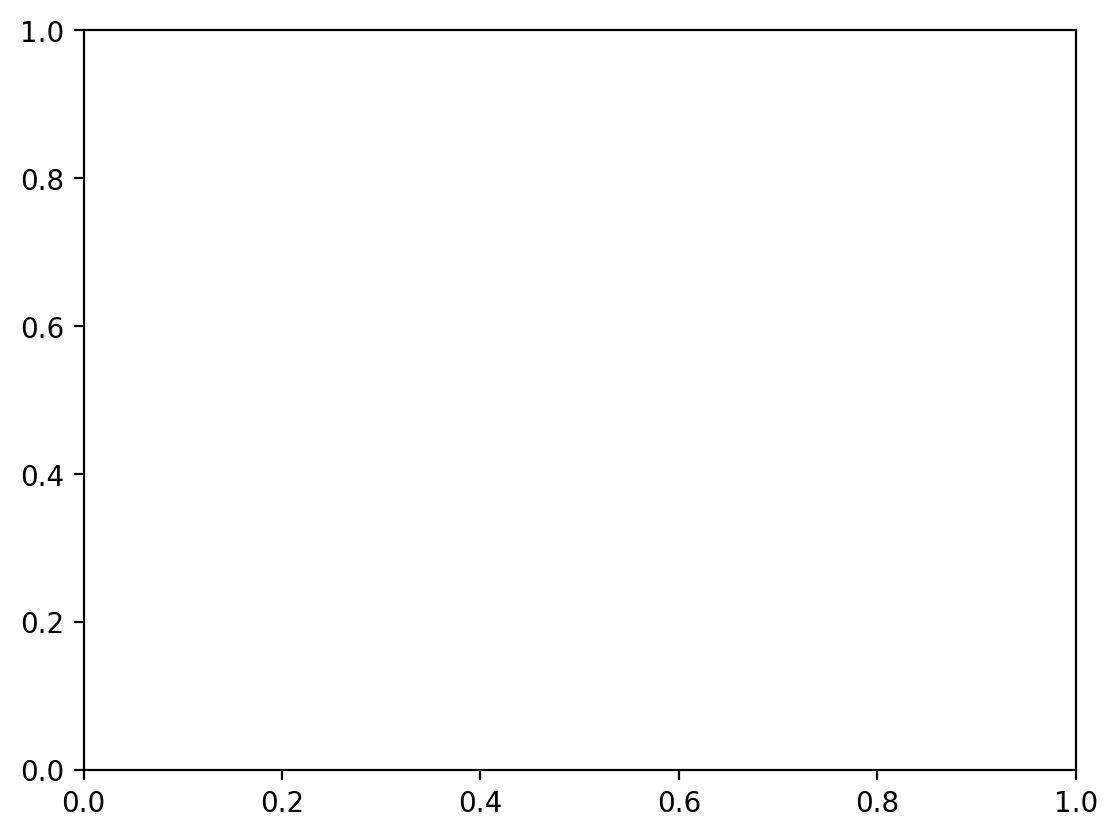

In [5]:
plt.contourf(ds)